# Validation: Batch Key = Dataset

- **Purpose:** Retrain the joint winner with `batch_key="dataset"` (tumor versus cell line) instead of the biological `batch` key.
- **Inputs:** Processed H5ADs; `models/hpo/best_models_primary_100.csv`; joint winner config and model.
- **Outputs:** `figures/HPOVAL/HPOVAL_dataset_batchkey.png`; artifacts under `models/validation/batchkey_dataset/`.
- **Result:** Using `dataset` as the model batch key collapses mixing (0.409 versus 0.692), so `batch` is kept.


Retrains the joint winner (config 10 / hvg3000) with the model batch key set
to `dataset` (2 levels: tumor vs cell line) instead of `batch`
(donor_chemistry / pool_id). Everything else is identical to the seed-0 HPO
run.

The evaluation deliberately keeps scIB on `batch`: with a 2-level model
batch key the tumor-only labeled benchmark would see a single batch and
degenerate, so the training batch key (`train_cfg`) and the evaluation batch
key (`eval_cfg`) are decoupled. The training config is recorded separately
in `config_train.json` next to the evaluation config.

With only 2 batch levels the model no longer
explicitly corrects tumor-internal donor structure. The tumor-only scIB
benchmark on `batch` and the within-tumor batch-purity diagnostic below show
whether the tumor structure survives while cross-domain mixing changes.


In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import torch
import scvi

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import hpo
from src import model_io
from src.utils import load_config

CFG = load_config()
PATHS = CFG["paths"]
HPO_CFG = CFG["hpo"]

adata_tumor = ad.read_h5ad(ROOT / PATHS["processed"]["pp_tumor"])
adata_cl = ad.read_h5ad(ROOT / PATHS["processed"]["pp_cell_line"])
print(f"tumor {adata_tumor.shape}, cell line {adata_cl.shape}")

tumor (108131, 28617), cell line (2162, 28617)


# Joint winner (fixed k=100)

In [2]:
best = pd.read_csv(ROOT / "models" / "hpo" / "best_models_primary_100.csv")
JOINT_RUN = ROOT / best.loc[best["approach"] == "joint", "run_dir"].iloc[0]
joint_cfg = json.loads((JOINT_RUN / "config.json").read_text())
print(JOINT_RUN)

/mnt/c/Users/marku/github/scMapping-public/models/hpo/runs/hvg3000/config_10/joint


## Train with batch_key = dataset

In [3]:
torch.set_float32_matmul_precision("high")
combined_3k = model_io.build_combined_adata_for_hvg(
    adata_tumor, adata_cl, joint_cfg["num_hvg"], hvg_dir=JOINT_RUN.parents[1]
)

train_cfg = {**joint_cfg, "batch_key": "dataset"}
hpo.set_seed(train_cfg["seed"])
dataset_dir = ROOT / "models" / "validation" / "batchkey_dataset" / "joint_hvg3000"
model_path = dataset_dir / "joint_scanvi"
if model_path.exists():
    print(f"[load] {model_path}")
    model = scvi.model.SCANVI.load(str(model_path), adata=combined_3k)
else:
    model = hpo.train_joint_scanvi(combined_3k, train_cfg, dataset_dir)
(dataset_dir / "config_train.json").write_text(hpo.json_dumps(train_cfg))

Seed set to 0


[load] /mnt/c/Users/marku/github/scMapping-public/models/validation/batchkey_dataset/joint_hvg3000/joint_scanvi
INFO     File                                                                                                      
         /mnt/c/Users/marku/github/scMapping-public/models/validation/batchkey_dataset/joint_hvg3000/joint_scanvi/m
         odel.pt already downloaded                                                                                


641

In [4]:
if hpo.is_run_done(dataset_dir):
    print("[skip] evaluation already done")
else:
    eval_cfg = {**train_cfg, "batch_key": "batch"}
    hpo.evaluate(
        model, combined_3k, eval_cfg, dataset_dir, "joint",
        scib_n_cells=HPO_CFG["scib_n_cells"],
    )
    hpo.mark_run_done(dataset_dir)

[skip] evaluation already done


# Within-tumor batch purity

Fraction of the k=100 nearest neighbors that share a tumor cell's own batch
(donor_chemistry), tumor cells only, for the HPO run (batch key `batch`)
versus the `dataset`-key run. A much higher value under the dataset key would
mean the tumor-internal donor structure is no longer corrected.

In [5]:
from sklearn.neighbors import NearestNeighbors


def tumor_batch_purity(model, combined, k=100):
    latent = model.get_latent_representation(combined)
    obs = combined.obs
    tumor_mask = (obs["dataset"] == "tumor").to_numpy()
    idx = np.where(tumor_mask)[0]
    nn = NearestNeighbors(n_neighbors=k + 1, n_jobs=1)
    nn.fit(latent[idx])
    _, ind = nn.kneighbors(latent[idx])
    ind = ind[:, 1:]
    batches = obs["batch"].to_numpy()[idx]
    return float((batches[ind] == batches[:, None]).mean())


baseline_model = scvi.model.SCANVI.load(str(JOINT_RUN / "joint_scanvi"), adata=combined_3k)
purity = {
    "joint HPO (batch_key=batch)": tumor_batch_purity(baseline_model, combined_3k),
    "joint dataset-key": tumor_batch_purity(model, combined_3k),
}
del baseline_model
purity

INFO     File                                                                                                      
         /mnt/c/Users/marku/github/scMapping-public/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt  
         already downloaded                                                                                        


{'joint HPO (batch_key=batch)': 0.10984167352563094,
 'joint dataset-key': 0.7894302281491894}

# Comparison

In [6]:
from src.validation import line_table, summary_row


In [7]:
out = pd.DataFrame({
    "joint HPO (batch_key=batch)": summary_row(JOINT_RUN),
    "joint dataset-key": summary_row(dataset_dir),
}).T
out["tumor_batch_purity_k100"] = pd.Series(purity)
out.round(4)

,mean_line_score,mean_mixing,mean_specificity,mean_coverage,mean_line_purity,scib_Total,scib_Batch_correction,scib_Bio_conservation,n_epochs,tumor_batch_purity_k100
joint HPO (batch_key=batch),0.6791,0.6923,0.9496,1.0000,0.5224,0.5929,0.5999,0.5883,75.0,0.1098
joint dataset-key,0.6598,0.4090,0.8561,0.9351,0.9167,0.4109,0.3170,0.4736,71.0,0.7894


In [8]:
pd.DataFrame({
    "joint HPO (batch)": line_table(JOINT_RUN)["line_score"],
    "joint dataset-key": line_table(dataset_dir)["line_score"],
}).round(4)

,joint HPO (batch),joint dataset-key
cell_line,,
NCIH747,0.5159,0.6780
LS1034,0.7719,0.7386
RCM1,0.6536,0.8074
CCK81,0.6314,0.5550
SNUC4,0.7122,0.3130
CL34,0.6493,0.6939
LS180,0.7547,0.5851
OUMS23,0.6438,0.6572
HCC56,0.7049,0.7467


# UMAP

In [9]:
baseline_model = scvi.model.SCANVI.load(str(JOINT_RUN / "joint_scanvi"), adata=combined_3k)

INFO     File                                                                                                      
         /mnt/c/Users/marku/github/scMapping-public/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt  
         already downloaded                                                                                        


In [10]:
combined_3k.obsm["X_dataset_key"] = model.get_latent_representation(combined_3k)
combined_3k.obsm["X_batch_key"] = baseline_model.get_latent_representation(combined_3k)

In [11]:
import scanpy as sc
sc.pp.neighbors(combined_3k, use_rep="X_batch_key", key_added="neigh_batch_key")
sc.pp.neighbors(combined_3k, use_rep="X_dataset_key", key_added="neigh_dataset_key")

sc.tl.umap(combined_3k, neighbors_key="neigh_batch_key", key_added="UMAP_batch")
sc.tl.umap(combined_3k, neighbors_key="neigh_dataset_key", key_added="UMAP_dataset")

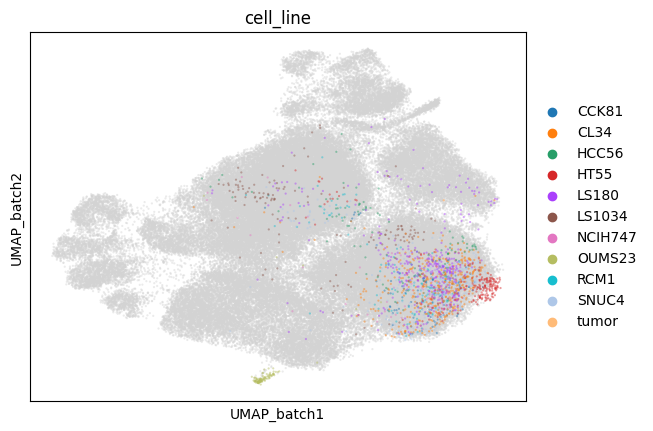

In [12]:
sc.pl.embedding(
    combined_3k,
    mask_obs=(combined_3k.obs.dataset=="cell_line"),
    color=["cell_line"],
    na_in_legend=False,
    size=10,
    alpha=0.45,
    basis="UMAP_batch",
)

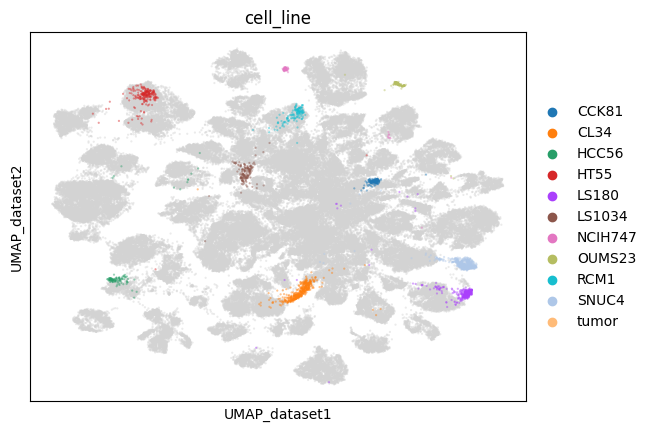

In [13]:
sc.pl.embedding(
    combined_3k,
    mask_obs=(combined_3k.obs.dataset=="cell_line"),
    color=["cell_line"],
    na_in_legend=False,
    size=10,
    alpha=0.45,
    basis="UMAP_dataset",
)

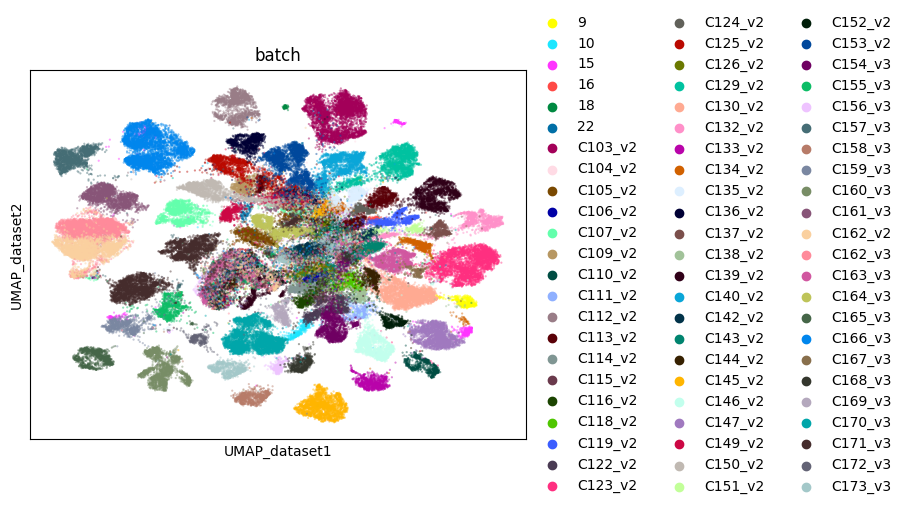

In [14]:
sc.pl.embedding(
    combined_3k,
    #mask_obs=(combined_3k.obs.dataset=="batch"),
    color=["batch"],
    na_in_legend=False,
    size=10,
    alpha=0.45,
    basis="UMAP_dataset",
)

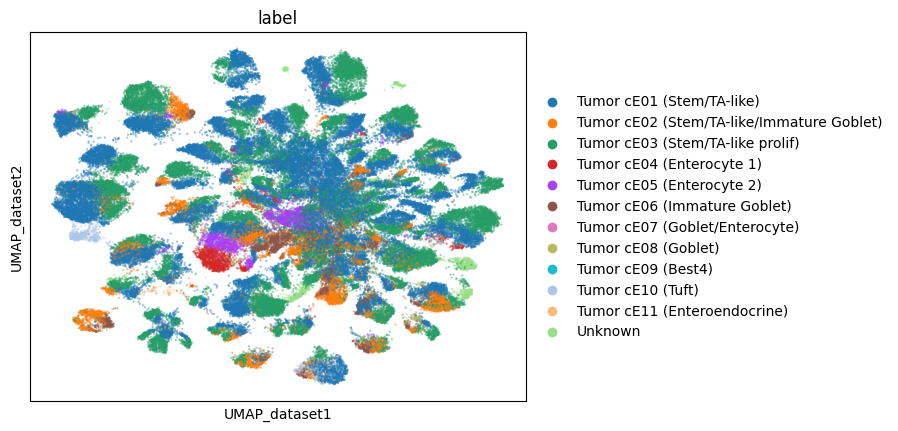

In [15]:
sc.pl.embedding(
    combined_3k,
    #mask_obs=(combined_3k.obs.dataset=="batch"),
    color=["label"],
    na_in_legend=False,
    size=10,
    alpha=0.45,
    basis="UMAP_dataset",
)

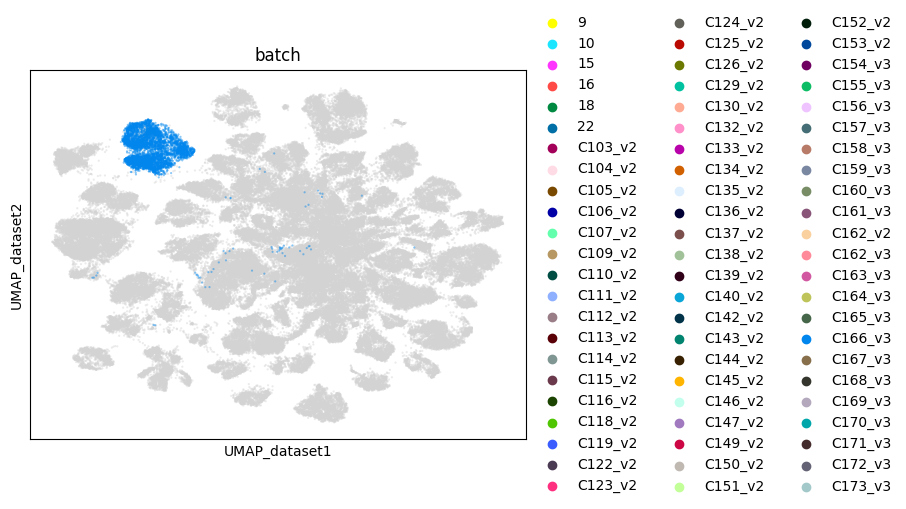

In [16]:
sc.pl.embedding(
    combined_3k,
    mask_obs=(combined_3k.obs.donor_id=="C166"),
    color=["batch"],
    na_in_legend=False,
    size=10,
    alpha=0.45,
    basis="UMAP_dataset",
)

# Visual for embed

In [17]:
import matplotlib.pyplot as plt

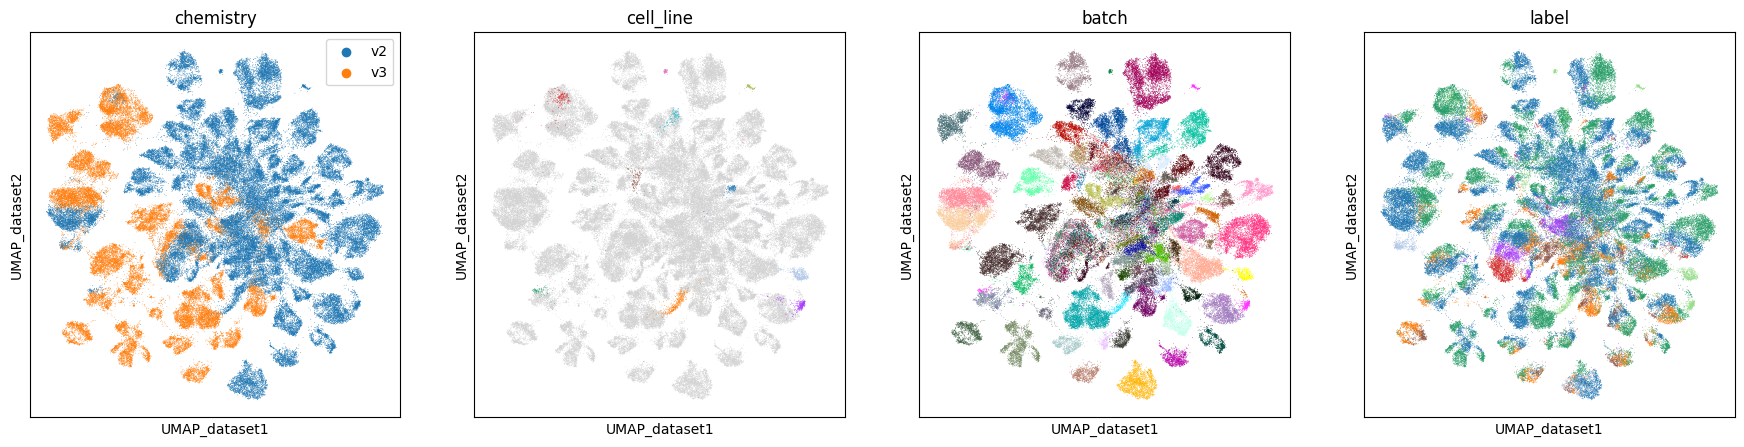

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
rng = np.random.default_rng(0)
combined_3k = combined_3k[rng.permutation(combined_3k.n_obs)].copy()
common = dict(
    basis = "UMAP_dataset",
    show=False
)
sc.pl.embedding(combined_3k, color="chemistry", ax=axes[0], legend_loc="upper right", **common)
sc.pl.embedding(combined_3k, mask_obs=(combined_3k.obs.dataset=="cell_line"), color="cell_line", ax=axes[1], legend_loc=None, **common)
sc.pl.embedding(combined_3k, color="batch", ax=axes[2], legend_loc=None, **common)
sc.pl.embedding(combined_3k, color="label", ax=axes[3], legend_loc=None, **common)

FIGS = ROOT / "figures" / "HPOVAL"
FIGS.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGS / "HPOVAL_dataset_batchkey.png", dpi=200, bbox_inches="tight")